# Preprocess

In [2]:
!pip install optuna
import pandas as pd
import numpy as np
import unicodedata

df = pd.read_excel('./base_churn_5000_VF2_aluno.xlsx')

with pd.option_context('display.max_columns', None):
    print(df.head())

# definição das datas base e de corte (final)
data_base = pd.to_datetime("21-09-2026", format="%d-%m-%Y")
data_corte = data_base + pd.Timedelta(days=60)

# transformação dos valores para datetime
df['data_aquisicao_cliente'] = pd.to_datetime(df['data_aquisicao_cliente'], format="mixed", dayfirst=True)
df['data_ocorrencia_churn'] = pd.to_datetime(df['data_ocorrencia_churn'], format="mixed", dayfirst=True)

# cria novo conjunto de clientes que deram churn ou não somente após a data base
df_60 = df[
    ((df['data_ocorrencia_churn'] >= data_base)
    | df['data_ocorrencia_churn'].isna())
].copy()

# cria uma coluna que informa os dias ativos de tal cliente
df_60['dias_ativo'] = (data_base - df_60['data_aquisicao_cliente']).dt.days

# remove os cliente com dias ativos menor que 60 dias
df_60 = df_60[df_60['dias_ativo'] >= 60].copy()

# cria uma coluna de meses ativos
df_60['tempo_cliente_meses'] = (df_60['dias_ativo'] / 30).astype(int)

  id_cliente data_aquisicao_cliente  mensalidade_rs            data_chamado  \
0      C0001             21/04/2024           67.96  09/09/2026, 15/08/2026   
1      C0002             21/02/2025           65.95                     NaN   
2      C0003             21/03/2025          100.88              28/08/2026   
3      C0004             21/03/2025           94.80  06/08/2026, 28/07/2026   
4      C0005             21/02/2022           53.68              05/07/2026   

   atrasos_6m tipo_contrato forma_pagamento  fibra_optica  debito_automatico  \
0         0.0        Bienal          Boleto             0                  0   
1         0.0        Mensal          Cartão             0                  0   
2         1.0         Anual          Boleto             1                  1   
3         2.0        Mensal          Cartão             0                  1   
4         2.0         Anual             Pix             0                  0   

  data_ocorrencia_churn  
0                 

In [3]:
# Granularidade do número de chamadas --------------------------------------------------------- #

# cria coluna com lista de datas de chamado, que é uma string em data_chamado
df_60['lista_chamados'] = df_60['data_chamado'].dropna().str.split(r',\s*').apply(lambda lista: pd.to_datetime(lista, format='%d/%m/%Y'))

# cria coluna para armazenar a quantidade total de chamados
df_60['numero_chamados_total'] = df_60.apply(
    lambda row: sum(
        row['data_aquisicao_cliente'] <= d <= data_base
        for d in row['lista_chamados']
    )
    if isinstance(row['lista_chamados'], pd.DatetimeIndex)
    else 0,
    axis=1,
)

# cria três colunas para armazenar o total de chamados nos períodos determinados
for dias in [30, 60, 90]:
    data_inicio = data_base - pd.Timedelta(days=dias)
    df_60[f'numero_chamados_{dias}_dias'] = df_60.apply(
        lambda row: sum(
            (row['data_aquisicao_cliente'] <= d <= data_base)
            and (d >= data_inicio)
            for d in row['lista_chamados']
        )
        if isinstance(row['lista_chamados'], pd.DatetimeIndex)
        else 0,
        axis=1,
    )

#Assumimos que se for NaN, o cliente não atrasou em nenhum momento (ANALISAR POSSÍVEIS USO DE MÉDIA/MEDIANA/KNN)
df_60['atrasos_6m'] = df_60['atrasos_6m'].replace(99, np.nan).fillna(0.0).astype(int)

#Se houve ocorrência de churn, 1, senão, 0.
df_60['churn'] = (df_60['data_ocorrencia_churn'].notna() & (df_60['data_ocorrencia_churn'] <= data_corte)).astype(int)

# deleta colunas que não serão utilizadas
df_60 = df_60.drop(columns = ['data_chamado', 'lista_chamados', 'data_aquisicao_cliente', 'data_ocorrencia_churn', 'dias_ativo'])

def padronizar_string(valor, coluna=None):
    if pd.isna(valor):
        return valor

    contratos = {
        'mensal': 'Mensal',
        'anual': 'Anual',
        'bienal': 'Bienal'
    }

    pagamentos = {
        'boleto': 'Boleto',
        'cartao': 'Cartão',
        'pix': 'Pix'
    }

    valor = str(valor).strip().lower()
    valor = unicodedata.normalize('NFKD', valor)
    valor = ''.join(
        caractere for caractere in valor
        if not unicodedata.combining(caractere)
    )

    if coluna == 'tipo_contrato':
        return contratos[valor]
    elif coluna == 'forma_pagamento':
        return pagamentos[valor]
    else:
        return valor


In [4]:
# Seleciona todas as colunas do tipo string
colunas_string = df_60.select_dtypes(include=['object', 'string']).columns

for coluna in colunas_string:
    df_60[coluna] = df_60[coluna].apply(padronizar_string, coluna=coluna)

with pd.option_context('display.max_columns', None):
    print(df_60.head())

df_60.to_excel('./base_churn_5000_VF2_aluno_preprocessada.xlsx', index=False)

print(df.columns)

  id_cliente  mensalidade_rs  atrasos_6m tipo_contrato forma_pagamento  \
0      c0001           67.96           0        Bienal          Boleto   
1      c0002           65.95           0        Mensal          Cartão   
2      c0003          100.88           1         Anual          Boleto   
3      c0004           94.80           2        Mensal          Cartão   
4      c0005           53.68           2         Anual             Pix   

   fibra_optica  debito_automatico  tempo_cliente_meses  \
0             0                  0                   29   
1             0                  0                   19   
2             1                  1                   18   
3             0                  1                   18   
4             0                  0                   55   

   numero_chamados_total  numero_chamados_30_dias  numero_chamados_60_dias  \
0                      2                        1                        2   
1                      0                    

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)


def analise_metricas(y_true, y_proba, threshold=0.5, titulo="Modelo"):
    """
    Painel de análise de um classificador binário (churn = 1).

    Gráficos:
      1. Precision, Recall e F1 em função do corte (threshold)
      2. Curva ROC (AUC)
      3. Curva Precision-Recall (PR-AUC)
      4. Kolmogorov-Smirnov (KS)
      5. Matriz de confusão no corte escolhido
      6. Lift por decil (quanto o topo do ranking concentra de churn)

    Parâmetros
      y_true    : rótulos reais (0/1)
      y_proba   : probabilidade prevista da classe 1
      threshold : corte usado para a matriz de confusão e para as métricas impressas
      titulo    : nome do modelo, usado no título da figura

    Retorna um dicionário com as métricas calculadas.
    """
    y_true = np.asarray(y_true).astype(int)
    y_proba = np.asarray(y_proba, dtype=float)
    y_pred = (y_proba >= threshold).astype(int)
    prevalencia = y_true.mean()

    # ------------------------- métricas escalares ------------------------- #
    roc_auc = roc_auc_score(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)
    precisao = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # KS: maior distância entre a distribuição acumulada dos scores de quem
    # deu churn e de quem não deu
    pos = np.sort(y_proba[y_true == 1])
    neg = np.sort(y_proba[y_true == 0])
    grade = np.linspace(y_proba.min(), y_proba.max(), 1000)
    cdf_pos = np.searchsorted(pos, grade, side="right") / len(pos)
    cdf_neg = np.searchsorted(neg, grade, side="right") / len(neg)
    dif_ks = np.abs(cdf_neg - cdf_pos)
    i_ks = int(dif_ks.argmax())
    ks = float(dif_ks[i_ks])

    # métricas para cada corte possível (gráfico 1)
    cortes = np.linspace(0.01, 0.99, 99)
    pred_c = y_proba[None, :] >= cortes[:, None]
    tp = (pred_c & (y_true == 1)).sum(axis=1)
    fp = (pred_c & (y_true == 0)).sum(axis=1)
    fn = (~pred_c & (y_true == 1)).sum(axis=1)
    prec_c = tp / np.maximum(tp + fp, 1)
    rec_c = tp / np.maximum(tp + fn, 1)
    f1_c = 2 * prec_c * rec_c / np.maximum(prec_c + rec_c, 1e-12)
    corte_f1 = float(cortes[f1_c.argmax()])

    # --------------------------------- resumo ------------------------------ #
    print(f"=== {titulo} ===")
    print(f"ROC-AUC : {roc_auc:.4f}   PR-AUC : {pr_auc:.4f}   KS : {ks:.4f}")
    print(f"Corte {threshold:.4f} -> Precision: {precisao:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    print(f"Corte que maximiza F1 nesta base: {corte_f1:.2f} (F1 = {f1_c.max():.4f})")

    # -------------------------------- gráficos ----------------------------- #
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"Análise de métricas - {titulo}", fontsize=15, fontweight="bold")

    # 1) Precision / Recall / F1 x corte
    ax = axes[0, 0]
    ax.plot(cortes, prec_c, label="Precision")
    ax.plot(cortes, rec_c, label="Recall")
    ax.plot(cortes, f1_c, label="F1", linewidth=2.5)
    ax.axvline(threshold, color="black", linestyle="--", label=f"Corte usado ({threshold:.2f})")
    ax.axvline(corte_f1, color="gray", linestyle=":", label=f"Melhor F1 ({corte_f1:.2f})")
    ax.set_xlabel("Corte (threshold)")
    ax.set_ylabel("Valor da métrica")
    ax.set_title("Precision, Recall e F1 por corte")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower center", fontsize=9)

    # 2) ROC
    ax = axes[0, 1]
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ax.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.4f}")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Aleatório")
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    ax.scatter(fp_t / max(fp_t + tn_t, 1), tp_t / max(tp_t + fn_t, 1),
               color="black", zorder=5, label=f"Corte {threshold:.2f}")
    ax.set_xlabel("Taxa de falsos positivos")
    ax.set_ylabel("Taxa de verdadeiros positivos (Recall)")
    ax.set_title("Curva ROC")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")

    # 3) Precision-Recall
    ax = axes[0, 2]
    prec_pr, rec_pr, _ = precision_recall_curve(y_true, y_proba)
    ax.plot(rec_pr, prec_pr, linewidth=2, label=f"PR-AUC = {pr_auc:.4f}")
    ax.axhline(prevalencia, color="gray", linestyle="--", label=f"Sem habilidade ({prevalencia:.3f})")
    ax.scatter(recall, precisao, color="black", zorder=5, label=f"Corte {threshold:.2f}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Curva Precision-Recall")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left")

    # 4) Kolmogorov-Smirnov
    ax = axes[1, 0]
    ax.plot(grade, cdf_neg, label="Não churn (acumulada)")
    ax.plot(grade, cdf_pos, label="Churn (acumulada)")
    ax.vlines(grade[i_ks], cdf_pos[i_ks], cdf_neg[i_ks], color="black", linewidth=2,
              label=f"KS = {ks:.4f} (score {grade[i_ks]:.2f})")
    ax.set_xlabel("Score previsto")
    ax.set_ylabel("Proporção acumulada")
    ax.set_title("Kolmogorov-Smirnov")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")

    # 5) Matriz de confusão
    ax = axes[1, 1]
    cm = np.array([[tn_t, fp_t], [fn_t, tp_t]])
    cm_pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1%} da linha)", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=12)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Prev. Não churn", "Prev. Churn"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real Não churn", "Real Churn"])
    ax.set_title(f"Matriz de confusão (corte {threshold:.2f})")

    # 6) Lift por decil
    ax = axes[1, 2]
    dados = pd.DataFrame({"y": y_true, "p": y_proba})
    dados["decil"] = pd.qcut(dados["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    lift = dados.groupby("decil", observed=True)["y"].mean() / prevalencia
    barras = ax.bar(range(1, 11), lift.values)
    ax.axhline(1, color="gray", linestyle="--", label="Média da base (lift = 1)")
    for barra, valor in zip(barras, lift.values):
        ax.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Decil (1 = maiores scores)")
    ax.set_ylabel("Lift (taxa de churn / taxa média)")
    ax.set_title("Lift por decil")
    ax.grid(alpha=0.3, axis="y")
    ax.legend(loc="upper right")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    return {
        "roc_auc": roc_auc, "pr_auc": pr_auc, "ks": ks,
        "precision": precisao, "recall": recall, "f1": f1,
        "threshold": threshold, "corte_melhor_f1": corte_f1,
    }

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import learning_curve, StratifiedKFold

def analise_overfitting(modelo, X_train, y_train, X_test, y_test, threshold=0.5, nome="Modelo"):
    # 1. Gap de Acurácia e Recall (Treino 70% vs Teste 30%)
    y_pred_train = (modelo.predict_proba(X_train)[:, 1] >= threshold).astype(int)
    y_pred_test  = (modelo.predict_proba(X_test)[:, 1]  >= threshold).astype(int)

    acc_tr, acc_te = accuracy_score(y_train, y_pred_train), accuracy_score(y_test, y_pred_test)
    rec_tr, rec_te = recall_score(y_train, y_pred_train),   recall_score(y_test, y_pred_test)

    print(f"=== Análise de Overfitting: {nome} (corte={threshold:.4f}) ===")
    print(f"Acurácia -> Treino: {acc_tr:.4f} | Teste: {acc_te:.4f} | Gap: {acc_tr - acc_te:+.4f}")
    print(f"Recall   -> Treino: {rec_tr:.4f} | Teste: {rec_te:.4f} | Gap: {rec_tr - rec_te:+.4f}")

    # 2. Curva de Aprendizado (Recall da classe Churn vs. tamanho da base de treino)
    # Remove early_stopping_rounds para rodar learning_curve sem eval_set
    params_lc = modelo.get_params()
    params_lc["early_stopping_rounds"] = None
    if hasattr(modelo, "best_iteration") and modelo.best_iteration is not None:
        params_lc["n_estimators"] = modelo.best_iteration + 1
    modelo_lc = modelo.__class__(**params_lc)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    tamanhos, scores_tr, scores_val = learning_curve(
        modelo_lc, X_train, y_train,
        cv=cv, scoring="recall",
        train_sizes=np.linspace(0.1, 1.0, 8),
        n_jobs=-1
    )

    plt.figure(figsize=(8, 5))
    plt.plot(tamanhos, scores_tr.mean(axis=1), "o-", label="Recall Treino")
    plt.plot(tamanhos, scores_val.mean(axis=1), "o-", label="Recall Validação (CV)")
    plt.fill_between(tamanhos, scores_tr.mean(axis=1) - scores_tr.std(axis=1),
                     scores_tr.mean(axis=1) + scores_tr.std(axis=1), alpha=0.15)
    plt.fill_between(tamanhos, scores_val.mean(axis=1) - scores_val.std(axis=1),
                     scores_val.mean(axis=1) + scores_val.std(axis=1), alpha=0.15)
    plt.title(f"Curva de Aprendizado (Recall) - {nome}")
    plt.xlabel("Quantidade de exemplos de treino")
    plt.ylabel("Recall (Classe Churn)")
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plotar_feature_importance(modelo, colunas, nome="XGBoost"):
    imp = pd.Series(modelo.feature_importances_, index=colunas).sort_values(ascending=True)
    plt.figure(figsize=(8, 5))
    imp.plot(kind="barh")
    plt.title(f"Ranking de Importância de Atributos - {nome}")
    plt.xlabel("Importância")
    plt.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()
    return imp.sort_values(ascending=False)

def print_metrics(y_true, proba, threshold, label):
    preds = (proba >= threshold).astype(int)
    print(f"\n--- {label} (threshold = {threshold:.4f}) ---")
    print(f"Precision: {precision_score(y_true, preds, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, preds, zero_division=0):.4f}")
    print(f"F1-Score:  {f1_score(y_true, preds, zero_division=0):.4f}")
    print(classification_report(y_true, preds, digits=4))

# XGBoost

Árvores usadas (early stopping): 177


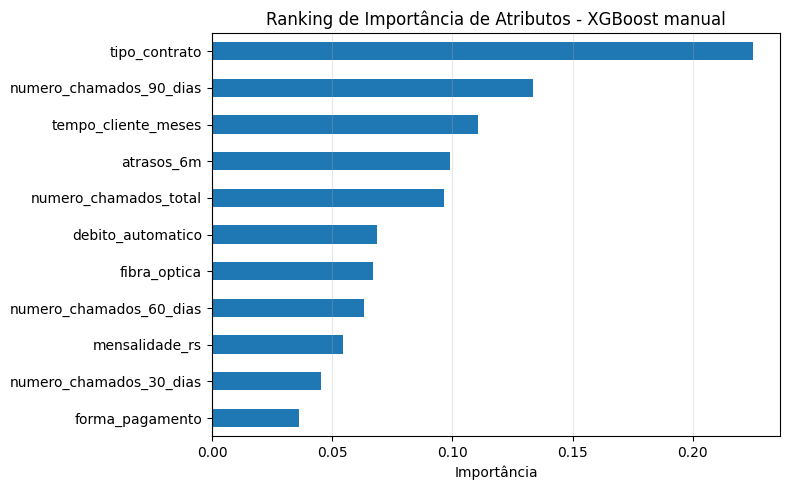

tipo_contrato              0.225031
numero_chamados_90_dias    0.133475
tempo_cliente_meses        0.110774
atrasos_6m                 0.098939
numero_chamados_total      0.096696
debito_automatico          0.068493
fibra_optica               0.067001
numero_chamados_60_dias    0.063426
mensalidade_rs             0.054573
numero_chamados_30_dias    0.045405
forma_pagamento            0.036186
dtype: float32

Classification Report (threshold = 0.20):
              precision    recall  f1-score   support

           0     0.9059    0.4773    0.6252       968
           1     0.4884    0.9096    0.6355       531

    accuracy                         0.6304      1499
   macro avg     0.6971    0.6934    0.6303      1499
weighted avg     0.7580    0.6304    0.6288      1499

=== XGBoost manual ===
ROC-AUC : 0.7963   PR-AUC : 0.6671   KS : 0.4433
Corte 0.2000 -> Precision: 0.4884 | Recall: 0.9096 | F1: 0.6355
Corte que maximiza F1 nesta base: 0.33 (F1 = 0.6507)


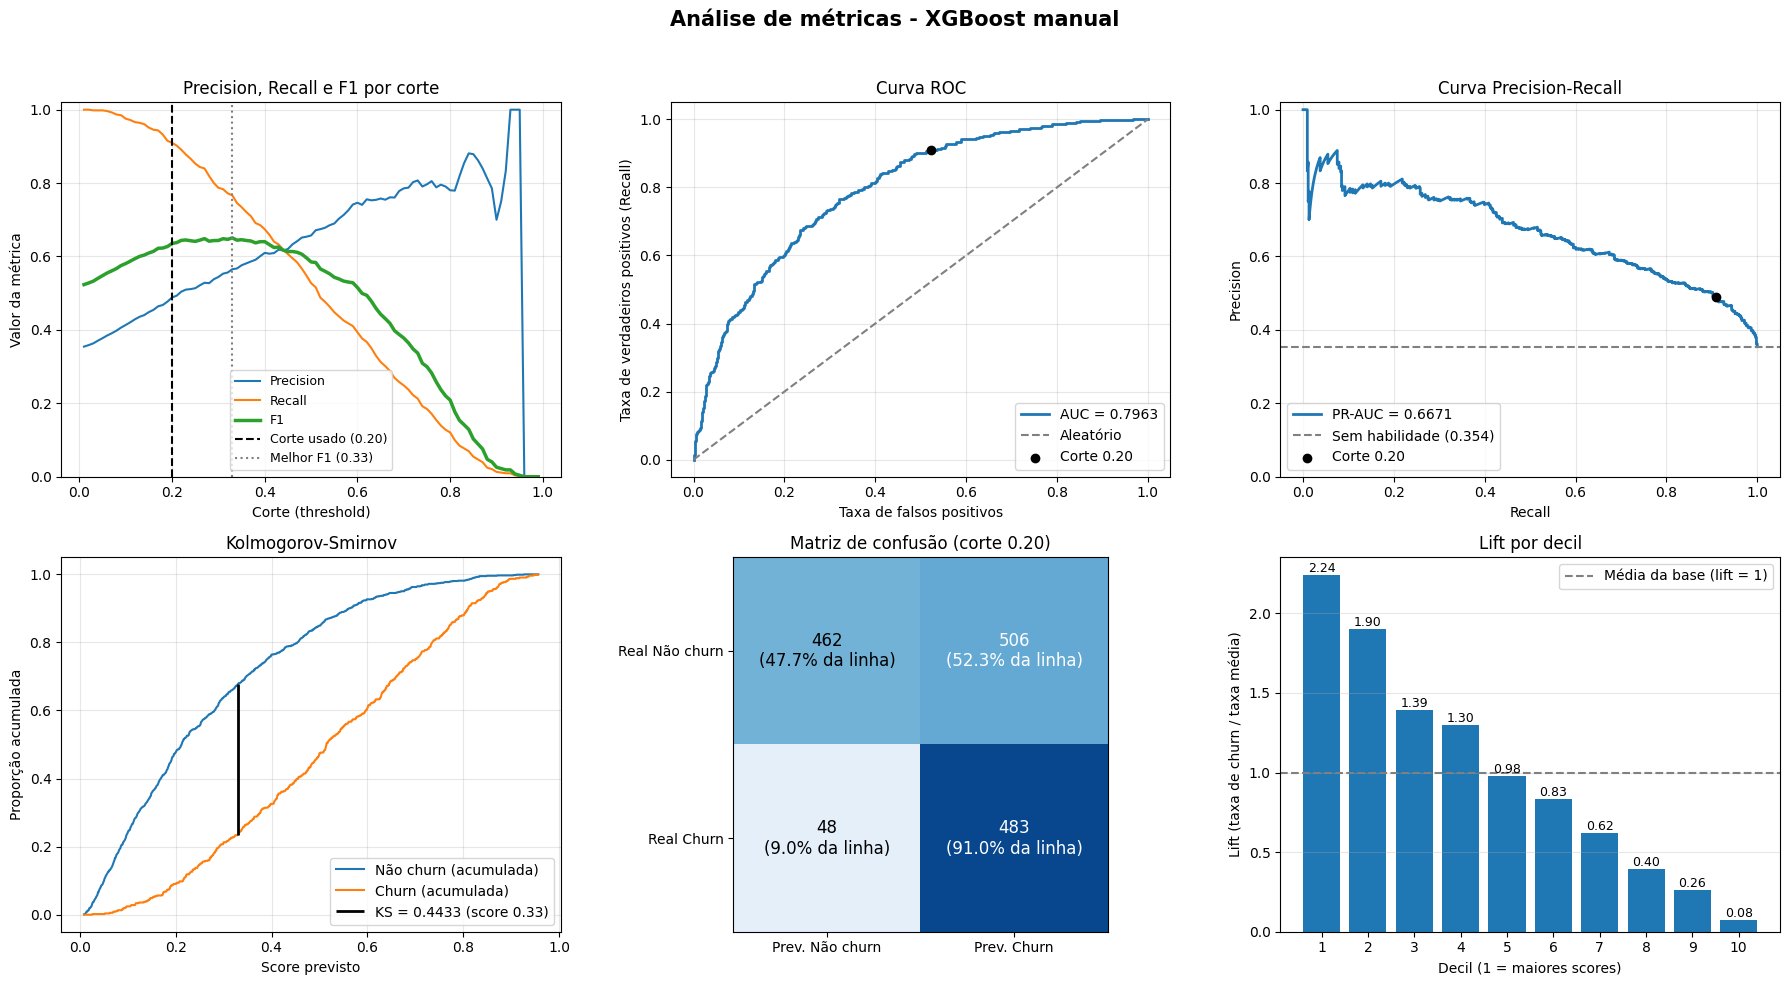

=== Análise de Overfitting: XGBoost manual (corte=0.2000) ===
Acurácia -> Treino: 0.6480 | Teste: 0.6304 | Gap: +0.0176
Recall   -> Treino: 0.9120 | Teste: 0.9096 | Gap: +0.0024


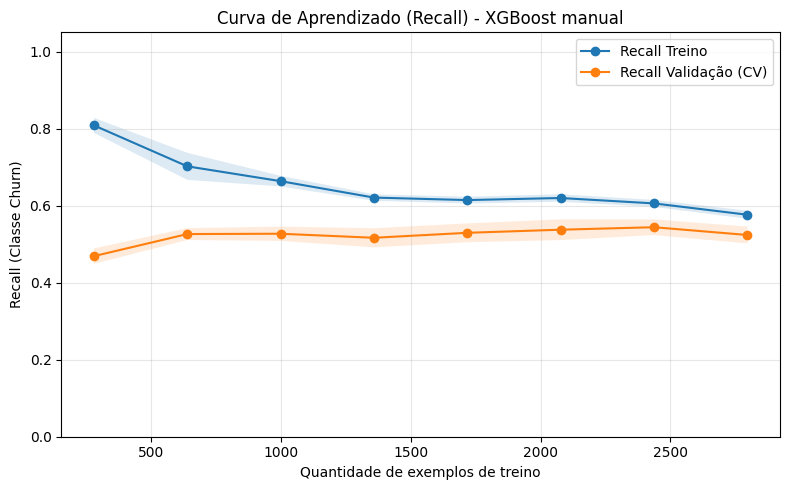

In [6]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# ============================================================================
# HIPERPARÂMETROS MANUAIS - edite os valores abaixo e rode a célula
# ============================================================================
HIPERPARAMETROS = {
    'n_estimators': 500,        # nº máximo de árvores (com early stopping, vira um teto)
    'learning_rate': 0.05,
    'max_depth': 3,
    'min_child_weight': 1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'gamma': 0.0,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0,
    'scale_pos_weight': 1.0,
}
EARLY_STOPPING_ROUNDS = 30   # None = desativa e treina exatamente n_estimators árvores
THRESHOLD = 0.2             # corte de classificação usado nas métricas e gráficos

df = pd.read_excel('./base_churn_5000_VF2_aluno_preprocessada.xlsx')
df = df.drop(columns=['id_cliente', 'ID_Cliente', 'cliente_id'], errors='ignore')

for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('category')

X = df.drop(columns=['churn'])
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# 2. Monta o modelo
params = {
    **HIPERPARAMETROS,
    'enable_categorical': True,
    'eval_metric': 'aucpr',
    'random_state': 42,
    'n_jobs': -1,
}

if EARLY_STOPPING_ROUNDS is not None:
    # O early stopping usa uma fatia de validação tirada do TREINO (o teste fica intocado)
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.3, stratify=y_train, random_state=42
    )
    model = xgb.XGBClassifier(**params, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    print(f"Árvores usadas (early stopping): {model.best_iteration + 1}")
else:
    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train, verbose=False)

# 3. Avalia no teste
y_proba = model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

ranking_xgb = plotar_feature_importance(model, X_train.columns, nome="XGBoost manual")
print(ranking_xgb)

print(f"\nClassification Report (threshold = {THRESHOLD:.2f}):")
print(classification_report(y_test, y_pred, digits=4))

# 4. Análise gráfica das métricas
analise_metricas(y_test, y_proba, threshold=THRESHOLD, titulo="XGBoost manual")
analise_overfitting(model, X_train, y_train, X_test, y_test, threshold=THRESHOLD, nome="XGBoost manual")


Best CV PR-AUC: 0.6648
Best Hyperparameters: {'learning_rate': 0.08133078763806557, 'max_depth': 3, 'min_child_weight': 29, 'subsample': 0.8621152971073255, 'colsample_bytree': 0.7271220698384386, 'gamma': 2.329400323706398, 'reg_alpha': 0.002062469812913097, 'reg_lambda': 0.4636751519218365, 'scale_pos_weight': 1.569206447663398}


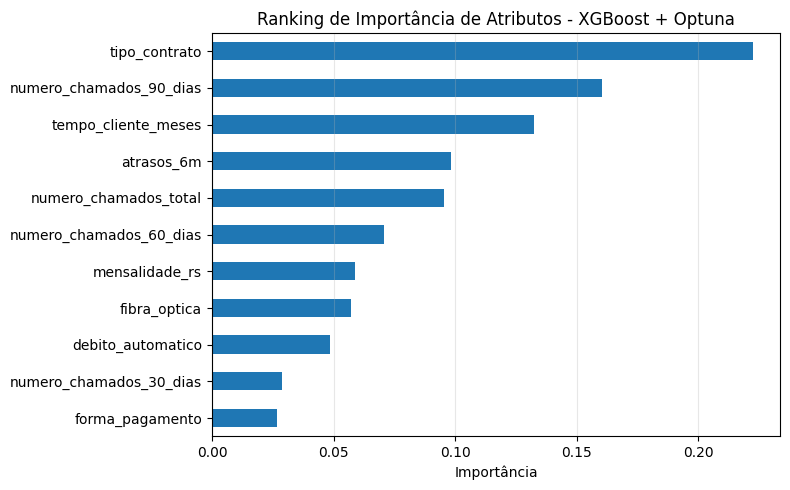

tipo_contrato              0.222485
numero_chamados_90_dias    0.160406
tempo_cliente_meses        0.132642
atrasos_6m                 0.098344
numero_chamados_total      0.095350
numero_chamados_60_dias    0.070772
mensalidade_rs             0.058957
fibra_optica               0.057091
debito_automatico          0.048663
numero_chamados_30_dias    0.028673
forma_pagamento            0.026616
dtype: float32

Test ROC-AUC: 0.8032
Test PR-AUC:  0.6855

--- Default Cutoff (threshold = 0.5000) ---
Precision: 0.6045
Recall:    0.7024
F1-Score:  0.6498
              precision    recall  f1-score   support

           0     0.8209    0.7479    0.7827       968
           1     0.6045    0.7024    0.6498       531

    accuracy                         0.7318      1499
   macro avg     0.7127    0.7252    0.7163      1499
weighted avg     0.7442    0.7318    0.7356      1499


--- Optimal F1 Cutoff (from CV) (threshold = 0.4476) ---
Precision: 0.5726
Recall:    0.7646
F1-Score:  0.6548
        

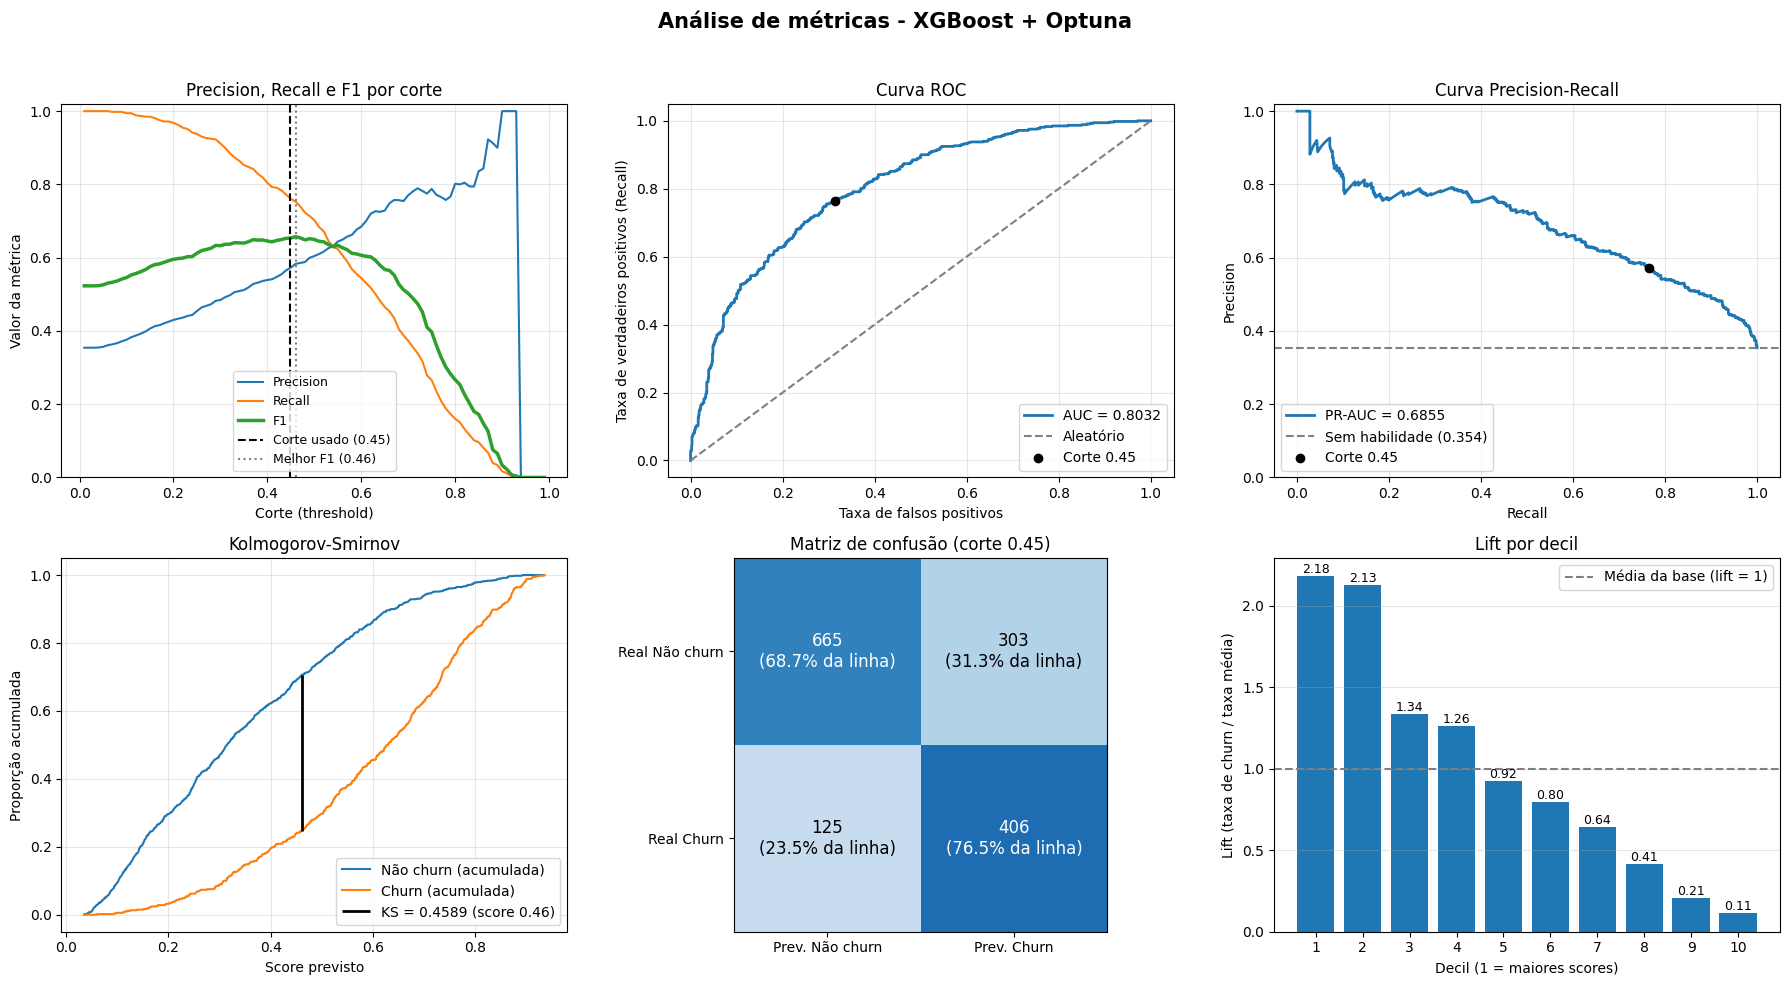

=== Análise de Overfitting: XGBoost + Optuna (corte=0.4476) ===
Acurácia -> Treino: 0.7229 | Teste: 0.7145 | Gap: +0.0084
Recall   -> Treino: 0.7595 | Teste: 0.7646 | Gap: -0.0051


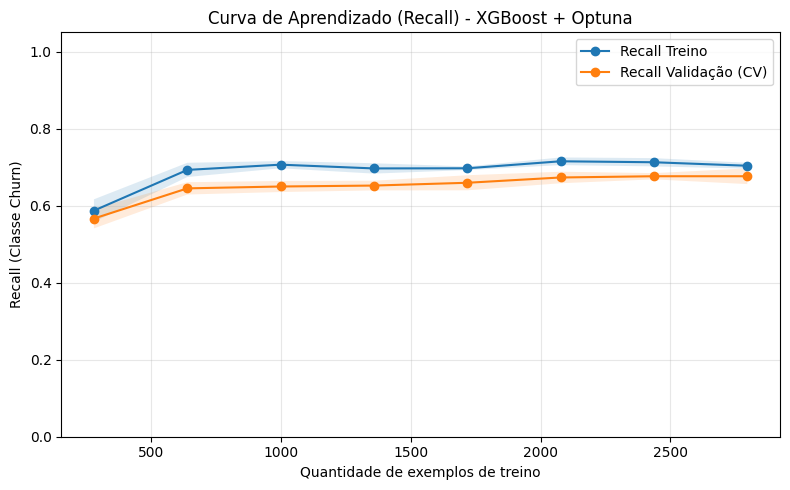

In [7]:
import numpy as np
import pandas as pd
import optuna
import xgboost as xgb
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Load preprocessed dataset
df = pd.read_excel('./base_churn_5000_VF2_aluno_preprocessada.xlsx')
df = df.drop(columns=['id_cliente', 'ID_Cliente', 'cliente_id'], errors='ignore')

for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype('category')

X = df.drop(columns=['churn'])
y = df['churn']

# Hold out 20% strictly for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

imbalance_ratio = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# 2. Optuna objective using 5-fold CV on X_train
def objective(trial):
    params = {
        'n_estimators': 1500,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 30),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, imbalance_ratio),
        'enable_categorical': True,
        'eval_metric': 'aucpr',
        'early_stopping_rounds': 30,
        'random_state': 42,
        'n_jobs': -1,
    }

    oof_preds = np.zeros(len(X_train))
    best_iterations = []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        oof_preds[val_idx] = model.predict_proba(X_val)[:, 1]
        best_iterations.append(model.best_iteration)

    # Save out-of-fold predictions and optimal tree count for the winning trial
    trial.set_user_attr('oof_preds', oof_preds)
    trial.set_user_attr('best_n_estimators', max(int(np.mean(best_iterations)), 50))

    return average_precision_score(y_train, oof_preds)


# 3. Run hyperparameter optimization (increase n_trials to 60-100 for final run)
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=40)

print(f"Best CV PR-AUC: {study.best_value:.4f}")
print("Best Hyperparameters:", study.best_params)

# 4. Find the threshold that maximizes F1 on out-of-fold training predictions
best_oof = study.best_trial.user_attrs['oof_preds']
precisions, recalls, thresholds = precision_recall_curve(y_train, best_oof)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_threshold = float(thresholds[np.argmax(f1_scores)])

# 5. Train final model on full X_train using the CV-selected tree count
final_params = {
    **study.best_params,
    'n_estimators': study.best_trial.user_attrs['best_n_estimators'],
    'enable_categorical': True,
    'random_state': 42,
    'n_jobs': -1,
}

final_model = xgb.XGBClassifier(**final_params)
final_model.fit(X_train, y_train)

# 6. Evaluate on X_test
y_proba = final_model.predict_proba(X_test)[:, 1]

ranking_xgb = plotar_feature_importance(final_model, X_train.columns, nome="XGBoost + Optuna")
print(ranking_xgb)

print(f"\nTest ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, y_proba):.4f}")

print_metrics(y_test, y_proba, 0.50, "Default Cutoff")
print_metrics(y_test, y_proba, best_threshold, "Optimal F1 Cutoff (from CV)")

# 7. Análise gráfica das métricas (teste, com o corte otimizado para F1)
analise_metricas(y_test, y_proba, threshold=best_threshold, titulo="XGBoost + Optuna")
analise_overfitting(final_model, X_train, y_train, X_test, y_test, threshold=best_threshold, nome="XGBoost + Optuna")

=== RECALL DA CLASSE CHURN ===
Recall treino: 59.52%
Recall teste:  52.73%
Gap de recall: 6.78%

Verdadeiros positivos (TP): 280
Falsos negativos (FN): 251
Falsos positivos (FP): 146

Precision: 65.73%
F1-score:  58.52%


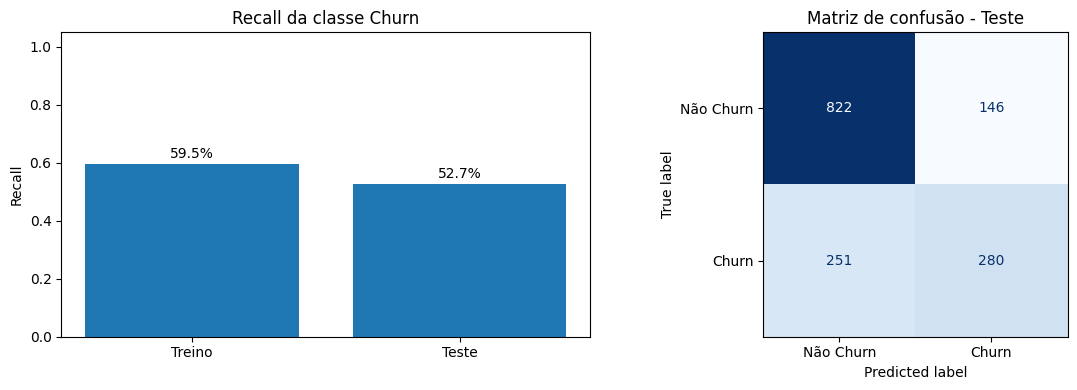

In [10]:
#Análise de Recall no churn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    recall_score, precision_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# Métrica principal: Recall da classe Churn (1)
LIMIAR = 0.50

# O modelo com early stopping foi ajustado sobre X_tr.
if EARLY_STOPPING_ROUNDS is not None:
    X_treino_eval, y_treino_eval = X_tr, y_tr
else:
    X_treino_eval, y_treino_eval = X_train, y_train

# Previsões
y_pred_train = (
    model.predict_proba(X_treino_eval)[:, 1] >= LIMIAR
).astype(int)

y_pred_test = (
    model.predict_proba(X_test)[:, 1] >= LIMIAR
).astype(int)

# Recall principal
recall_train = recall_score(y_treino_eval, y_pred_train)
recall_test = recall_score(y_test, y_pred_test)

# Métricas complementares
precision = precision_score(y_test, y_pred_test, zero_division=0)
f1 = f1_score(y_test, y_pred_test, zero_division=0)
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_test, labels=[0, 1]
).ravel()

print("=== RECALL DA CLASSE CHURN ===")
print(f"Recall treino: {recall_train:.2%}")
print(f"Recall teste:  {recall_test:.2%}")
print(f"Gap de recall: {recall_train - recall_test:.2%}")

print(f"\nVerdadeiros positivos (TP): {tp}")
print(f"Falsos negativos (FN): {fn}")
print(f"Falsos positivos (FP): {fp}")

print(f"\nPrecision: {precision:.2%}")
print(f"F1-score:  {f1:.2%}")

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(["Treino", "Teste"], [recall_train, recall_test])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Recall da classe Churn")
axes[0].set_ylabel("Recall")

for i, valor in enumerate([recall_train, recall_test]):
    axes[0].text(i, valor + 0.02, f"{valor:.1%}", ha="center")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=["Não Churn", "Churn"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Matriz de confusão - Teste")

plt.tight_layout()
plt.show()
